In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import seaborn as sns

In [2]:
#Loading both datasets using relative paths

df = pd.read_csv(r'../data/raw/diabetic_data.csv')
ids_mapping = pd.read_csv('../data/raw/IDS_mapping.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [4]:
df.shape

(101766, 50)

In [5]:
df.head(10)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
# Replace '?' with standard NaN across the entire dataframe
df = df.replace('?', np.nan)

# Check which columns actually have missing values and how many
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

print(f"Columns with missing values:\n{missing_data}")

Columns with missing values:
weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64


In [7]:
# Dropping weight (true missing data / 96% gone)
df = df.drop(columns=['weight'], errors='ignore')

# Changing the data type of 'medical_specialty' and 'payer_code' to string to handle missing values
df['medical_specialty'] = df['medical_specialty'].fillna('Unknown')
df['payer_code'] = df['payer_code'].fillna('Unknown')

# Fill missing diagnosis codes with 'None' (indicating no additional secondary or tertiary diagnosis)
df['diag_1'] = df['diag_1'].fillna('None')
df['diag_2'] = df['diag_2'].fillna('None')
df['diag_3'] = df['diag_3'].fillna('None')

# Drop negligible missing rows in demographics
df = df.dropna(subset=['race'])

print("Cleaned shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Cleaned shape: (99493, 49)
Remaining missing values: 177100


In [8]:
# Checking original distribution
print("Original Target Distribution:")
print(df['readmitted'].value_counts())

Original Target Distribution:
readmitted
NO     53317
>30    35007
<30    11169
Name: count, dtype: int64


In [9]:
# Creating a new binary target column (1 = readmitted <30 days, 0 = otherwise)
df['target'] = (df['readmitted'] == '<30').astype(int)

In [10]:
df.describe(include='object') 

,race,gender,age,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,A1Cresult,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,99493,99493,99493,99493,99493,99493,99493,99493,5290,16596,...,99493,99493,99493,99493,99493,99493,99493,99493,99493,99493
unique,5,3,10,17,73,715,746,787,3,3,...,1,4,4,2,2,1,2,2,2,3
top,Caucasian,Female,[70-80),Unknown,Unknown,428,276,250,Norm,>8,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,53575,25469,39712,48766,6739,6638,11227,2571,7961,...,99493,46496,98813,99480,99492,99493,99492,53582,76492,53317


In [11]:
# Mapping age bracket categories to their numerical midpoints for modeling purposees
# This converts ordinal strings (e.g., '[70-80)') into continuous integers to preserve the mathematical relationship of age for the model.
age_mapping = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

df['age'] = df['age'].map(age_mapping)

# Verifying the transformation
print("Updated Age Distribution:")
print(df['age'].value_counts().sort_index())

Updated Age Distribution:
age
5       160
15      682
25     1611
35     3699
45     9465
55    16895
65    21988
75    25469
85    16800
95     2724
Name: count, dtype: int64


In [12]:
def map_icd9(code):
    # Handle missing or explicitly unknown codes
    if code == 'None' or code == '?' or pd.isna(code):
        return 'Missing/Unknown'
    
    # ICD-9 codes starting with V or E are supplemental/external events
    if str(code).startswith('V') or str(code).startswith('E'):
        return 'Other'
    
    # Any code starting with 250 indicates Diabetes
    if str(code).startswith('250'):
        return 'Diabetes'
    
    # Try converting the remaining numeric codes to map to clinical systems
    try:
        num = float(code)
        
        if (390 <= num <= 459) or num == 785:
            return 'Circulatory'
        elif (460 <= num <= 519) or num == 786:
            return 'Respiratory'
        elif (520 <= num <= 579) or num == 787:
            return 'Digestive'
        elif (580 <= num <= 629) or num == 788:
            return 'Genitourinary'
        elif (140 <= num <= 239):
            return 'Neoplasms'
        elif (710 <= num <= 739):
            return 'Musculoskeletal'
        elif (800 <= num <= 999):
            return 'Injury'
        else:
            return 'Other'
            
    except ValueError:
        # Fallback for any unexpected string formats
        return 'Other'

# Apply the mapping function to all three diagnosis columns
for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].apply(map_icd9)

# Verify the new distribution for the primary diagnosis
print("Grouped Primary Diagnosis (diag_1):")
print(df['diag_1'].value_counts())

Grouped Primary Diagnosis (diag_1):
diag_1
Circulatory        29754
Other              17726
Respiratory        14109
Digestive           9297
Diabetes            8568
Injury              6815
Genitourinary       5026
Musculoskeletal     4826
Neoplasms           3353
Missing/Unknown       19
Name: count, dtype: int64


In [13]:
# List of medication columns
med_columns = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 
    'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 
    'miglitol', 'troglitazone', 'tolazamide', 'examide', 
    'citoglipton', 'insulin', 'glyburide-metformin', 
    'glipizide-metformin', 'glimepiride-pioglitazone', 
    'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# Converting medication columns to categorical for XGBoost
df[med_columns] = df[med_columns].astype('category')

# Verifying the conversion
print("Medication columns successfully converted to 'category'.")
print("Example (insulin):")
print(df['insulin'].value_counts())

Medication columns successfully converted to 'category'.
Example (insulin):
insulin
No        46496
Steady    29902
Down      12039
Up        11056
Name: count, dtype: int64


In [14]:
# Finding medication columns that only have 1 unique value across the entire dataset
zero_variance_meds = [col for col in med_columns if df[col].nunique() == 1]

print("Medications with only ONE value (zero predictive power):")
for med in zero_variance_meds:
    print(f"- {med}: contains only {df[med].unique()[0]}")

Medications with only ONE value (zero predictive power):
- examide: contains only No
- citoglipton: contains only No
- metformin-rosiglitazone: contains only No


In [15]:
# Dropping zero variance medication columns
df = df.drop(columns=zero_variance_meds, errors="ignore")

In [16]:
# Cleaning and encoding Gender
df = df[df['gender'] != 'Unknown/Invalid'] # Dropping the 3 /unknown rows since statistically insignificant
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})

# Encode Change and DiabetesMed
df['change'] = df['change'].map({'No': 0, 'Ch': 1})
df['diabetesMed'] = df['diabetesMed'].map({'No': 0, 'Yes': 1})

# Convert Race to categorical since no inherent mathematical ranking for XGBoost
df['race'] = df['race'].astype('category')

# Verifying the transformations
print("Gender (0=Female, 1=Male):\n", df['gender'].value_counts())
print("\nChange (0=No, 1=Yes):\n", df['change'].value_counts())
print("\nDiabetes Medication (0=No, 1=Yes):\n", df['diabetesMed'].value_counts())
print("\nRace dtype:", df['race'].dtype)

Gender (0=Female, 1=Male):
 gender
0    53575
1    45917
Name: count, dtype: int64

Change (0=No, 1=Yes):
 change
0    53582
1    45910
Name: count, dtype: int64

Diabetes Medication (0=No, 1=Yes):
 diabetesMed
1    76491
0    23001
Name: count, dtype: int64

Race dtype: category


In [17]:
# Encoding A1C and Glucose results (None=0, Normal=1, High=2, Very High=3)
a1c_mapping = {'None': 0, 'Norm': 1, '>7': 2, '>8': 3}
glu_mapping = {'None': 0, 'Norm': 1, '>200': 2, '>300': 3}

df['A1Cresult'] = df['A1Cresult'].map(a1c_mapping)
df['max_glu_serum'] = df['max_glu_serum'].map(glu_mapping)

# Keep only the first encounter for each patient to ensure independent observations so model doesn't count diff encounters as separate patients
df = df.sort_values('encounter_id').drop_duplicates(subset=['patient_nbr'], keep='first')

# Dropping the ID columns since they hold no predictive medical value, and so model doesn't overfit
df = df.drop(columns=['encounter_id', 'patient_nbr'], errors='ignore')

print("Final dataset shape after removing duplicate patients:", df.shape)

Final dataset shape after removing duplicate patients: (69667, 45)


/var/folders/y_/5j08sflx0r5czbk672bqhhgc0000gp/T/ipykernel_53095/2005372889.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='target', palette='Set2')


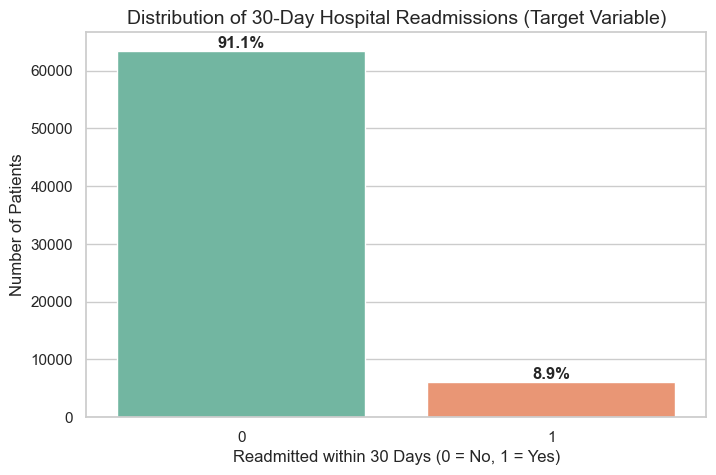

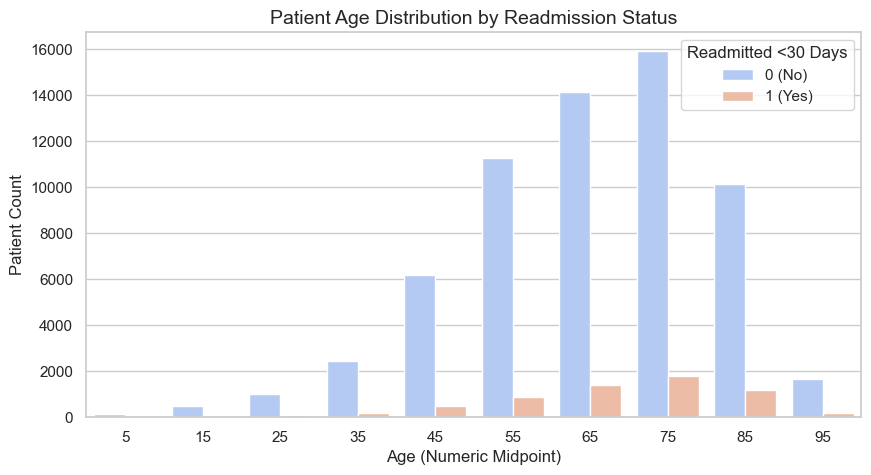

/var/folders/y_/5j08sflx0r5czbk672bqhhgc0000gp/T/ipykernel_53095/2005372889.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='diag_1', order=df['diag_1'].value_counts().index, palette='viridis')


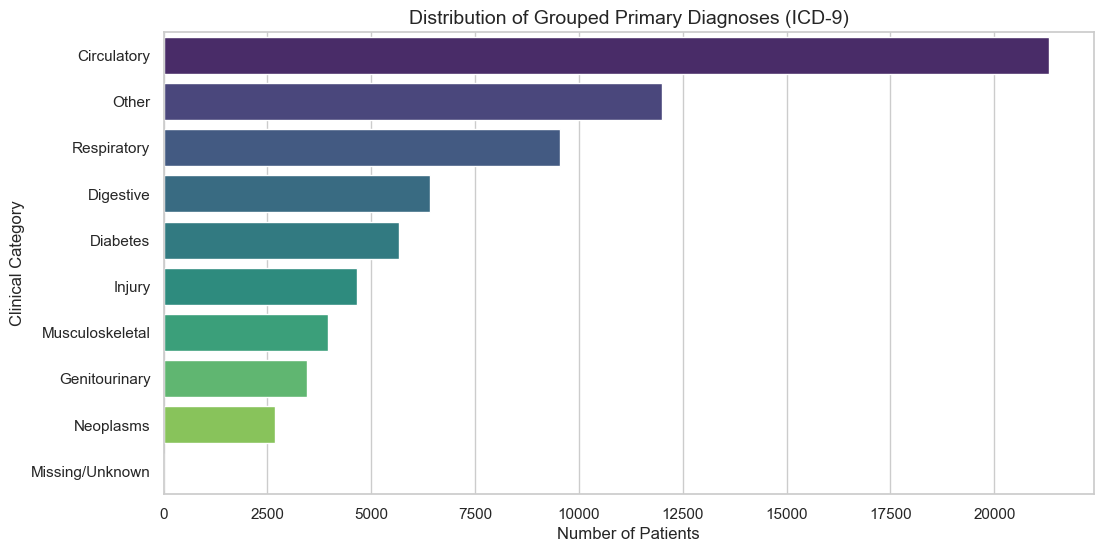

In [18]:
sns.set_theme(style="whitegrid")

# Plot 1: Target Class Imbalance
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='target', palette='Set2')
plt.title('Distribution of 30-Day Hospital Readmissions (Target Variable)', fontsize=14)
plt.xlabel('Readmitted within 30 Days (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

# Adding exact percentage labels on top of the bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height() + 500
    ax.annotate(percentage, (x, y), ha='center', fontsize=12, fontweight='bold')
plt.show()

# Plot 2: Age Distribution by Readmission

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='age', hue='target', palette='coolwarm')
plt.title('Patient Age Distribution by Readmission Status', fontsize=14)
plt.xlabel('Age (Numeric Midpoint)', fontsize=12)
plt.ylabel('Patient Count', fontsize=12)
plt.legend(title='Readmitted <30 Days', labels=['0 (No)', '1 (Yes)'])
plt.show()

# Plot 3: Grouped Primary Diagnosis

plt.figure(figsize=(12, 6))
# y='diag_1' makes it a horizontal bar chart, which is much easier to read for long category names
sns.countplot(data=df, y='diag_1', order=df['diag_1'].value_counts().index, palette='viridis')
plt.title('Distribution of Grouped Primary Diagnoses (ICD-9)', fontsize=14)
plt.xlabel('Number of Patients', fontsize=12)
plt.ylabel('Clinical Category', fontsize=12)
plt.show()

In [19]:
import os

# Create the data/processed directory if it doesn't already exist
os.makedirs('data/processed', exist_ok=True)

# Save the fully processed dataset to the specific folder
df.to_csv('data/processed/cleaned_diabetic_data.csv', index=False)